## **Problem Statement**

### Business Context

The prices of the stocks of companies listed under a global exchange are influenced by a variety of factors, with the company's financial performance, innovations and collaborations, and market sentiment being factors that play a significant role. News and media reports can rapidly affect investor perceptions and, consequently, stock prices in the highly competitive financial industry. With the sheer volume of news and opinions from a wide variety of sources, investors and financial analysts often struggle to stay updated and accurately interpret its impact on the market. As a result, investment firms need sophisticated tools to analyze market sentiment and integrate this information into their investment strategies.

### Problem Definition

With an ever-rising number of news articles and opinions, an investment startup aims to leverage artificial intelligence to address the challenge of interpreting stock-related news and its impact on stock prices. They have collected historical daily news for a specific company listed under NASDAQ, along with data on its daily stock price and trade volumes.

As a member of the Data Science and AI team in the startup, you have been tasked with developing an AI-driven sentiment analysis system that will automatically process and analyze news articles to gauge market sentiment, and summarizing the news at a weekly level to enhance the accuracy of their stock price predictions and optimize investment strategies. This will empower their financial analysts with actionable insights, leading to more informed investment decisions and improved client outcomes.

### Data Dictionary

* `Date` : The date the news was released
* `News` : The content of news articles that could potentially affect the company's stock price
* `Open` : The stock price (in \$) at the beginning of the day
* `High` : The highest stock price (in \$) reached during the day
* `Low` :  The lowest stock price (in \$) reached during the day
* `Close` : The adjusted stock price (in \$) at the end of the day
* `Volume` : The number of shares traded during the day
* `Label` : The sentiment polarity of the news content
    * 1: positive
    * 0: neutral
    * -1: negative

## **Installing and Importing the necessary libraries**

In [ ]:
# installing the sentence-transformers and gensim libraries for word embeddings
!pip install numpy==1.26.4 \
             scikit-learn==1.6.1 \
             scipy==1.13.1 \
             gensim==4.3.3 \
             sentence-transformers==3.4.1 \
             pandas==2.2.2

Note:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
# To manipulate and analyze data
import pandas as pd
pd.set_option('display.float_format', lambda x: '%.3f' % x) #supress scientific notation
import numpy as np
import os, sys, time


# To visualize data
import matplotlib.pyplot as plt
import seaborn as sns

# To build, tune, and evaluate ML models
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


# To load/create word embeddings
from gensim.models import Word2Vec

# To work with transformer models
import torch
from sentence_transformers import SentenceTransformer

# Import TensorFlow and Keras for deep learning model building.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# To implement progress bar related functionalities
from tqdm import tqdm
tqdm.pandas()

# To ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

from google.colab import files




## **Loading the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = "/content/drive/MyDrive/GABA/stock_news.csv"
df = pd.read_csv(path)

df.head()

,Date,News,Open,High,Low,Close,Volume,Label
0,2019-01-02,The tech sector experienced a significant dec...,41.740,42.245,41.482,40.247,130672400,-1
1,2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740,42.245,41.482,40.247,130672400,-1
2,2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740,42.245,41.482,40.247,130672400,-1
3,2019-01-02,This news article reports that yields on long...,41.740,42.245,41.482,40.247,130672400,-1
4,2019-01-02,Apple's revenue warning led to a decline in U...,41.740,42.245,41.482,40.247,130672400,-1


## **Data Overview**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349 entries, 0 to 348
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    349 non-null    object 
 1   News    349 non-null    object 
 2   Open    349 non-null    float64
 3   High    349 non-null    float64
 4   Low     349 non-null    float64
 5   Close   349 non-null    float64
 6   Volume  349 non-null    int64  
 7   Label   349 non-null    int64  
dtypes: float64(4), int64(2), object(2)
memory usage: 21.9+ KB


In [ ]:
df.shape

(349, 8)

In [ ]:
# there appears to be no missing data, but doing this just in case:
df.dropna(inplace=True)


In [ ]:
#Checking if object columns contain unique values
object_uniqueness = {
    col: df[col].is_unique
    for col in df.select_dtypes(include="object").columns
}

print(object_uniqueness)
# Date is not uniqu but 'News' is unique across all rows.

{'Date': False, 'News': True}


## **Exploratory Data Analysis**

### **Univariate Analysis**

* Distribution of individual variables
* Compute and check the distribution of the length of news content

In [ ]:

#Checking basic count, mean, std, min, 25%, 50%, 75%, max for each numeric column

# Select numeric columns only
numeric_df = df.select_dtypes(include=["float64", "int64"])

# Get summary statistics
numeric_df.describe().T


,count,mean,std,min,25%,50%,75%,max
Open,349.000,46.229,6.443,37.568,41.740,45.975,50.708,66.817
High,349.000,46.700,6.507,37.818,42.245,46.025,50.850,67.062
Low,349.000,45.745,6.392,37.305,41.482,45.640,49.778,65.863
Close,349.000,44.926,6.398,36.254,40.247,44.597,49.111,64.805
Volume,349.000,128948236.103,43170314.919,45448000.000,103272000.000,115627200.000,151125200.000,244439200.000
Label,349.000,-0.054,0.715,-1.000,-1.000,0.000,0.000,1.000


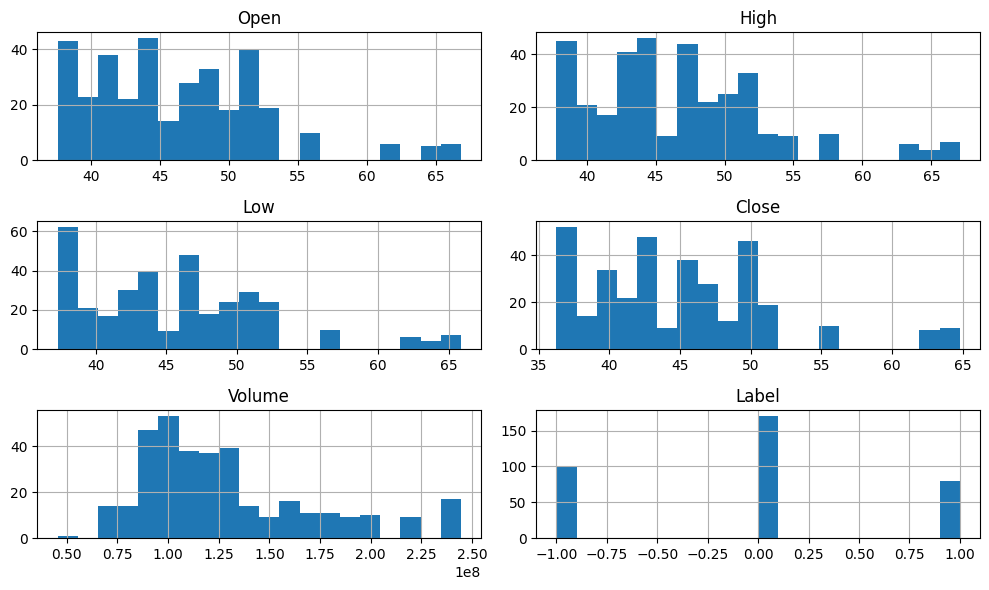

In [ ]:
#histograms for each numeric column
import matplotlib.pyplot as plt

numeric_df.hist(bins=20, figsize=(10, 6))
plt.tight_layout()
plt.show()


In [ ]:
# Create a helper that summarizes distributions for numeric columns (float & int)
import pandas as pd
import numpy as np

def summarize_numeric(df: pd.DataFrame) -> pd.DataFrame:
    numeric_df = df.select_dtypes(include=["float64", "int64", "float32", "int32", "Int64", "Float64"])
    rows = []
    for col in numeric_df.columns:
        s = numeric_df[col]
        s_no_na = s.dropna()
        if s_no_na.empty:
            stats = {
                "column": col,
                "dtype": s.dtype.name,
                "count": int(s.size),
                "missing": int(s.isna().sum()),
                "mean": np.nan,
                "std": np.nan,
                "min": np.nan,
                "p25": np.nan,
                "median": np.nan,
                "p75": np.nan,
                "max": np.nan,
                "skew": np.nan,
                "kurtosis": np.nan,
                "n_unique": 0,
                "pct_unique": np.nan,
                "mode": np.nan,
                "mode_freq": 0,
                "iqr": np.nan,
                "range": np.nan,
            }
        else:
            mode_series = s_no_na.mode()
            mode_val = mode_series.iloc[0] if not mode_series.empty else np.nan
            mode_freq = int((s_no_na == mode_val).sum()) if not np.isnan(mode_val) else 0
            stats = {
                "column": col,
                "dtype": s.dtype.name,
                "count": int(s.size),
                "missing": int(s.isna().sum()),
                "mean": s_no_na.mean(),
                "std": s_no_na.std(),
                "min": s_no_na.min(),
                "p25": s_no_na.quantile(0.25),
                "median": s_no_na.median(),
                "p75": s_no_na.quantile(0.75),
                "max": s_no_na.max(),
                "skew": s_no_na.skew(),
                "kurtosis": s_no_na.kurt(),
                "n_unique": int(s_no_na.nunique(dropna=True)),
                "pct_unique": float(s_no_na.nunique(dropna=True)) / float(s.size),
                "mode": mode_val,
                "mode_freq": mode_freq,
                "iqr": s_no_na.quantile(0.75) - s_no_na.quantile(0.25),
                "range": s_no_na.max() - s_no_na.min(),
            }
        rows.append(stats)
    summary = pd.DataFrame(rows).set_index("column")
    # Order columns nicely
    summary = summary[[
        "dtype","count","missing","n_unique","pct_unique",
        "mean","median","std","min","p25","p75","max",
        "iqr","range","skew","kurtosis","mode","mode_freq"
    ]]
    return summary

# --- Demo on a small example so you can see the output structure ---
np.random.seed(1)
df_example = pd.DataFrame({
    "age": np.random.randint(18, 70, size=100),
    "income": np.random.normal(60000, 15000, size=100),
    "score": np.random.beta(2, 5, size=100) * 100,
    "group": np.random.choice(list("ABCD"), size=100)  # non-numeric column; will be ignored
})



In [ ]:
summary = summarize_numeric(df)   # replace df with your DataFrame
summary


,dtype,count,missing,n_unique,pct_unique,mean,median,std,min,p25,p75,max,iqr,range,skew,kurtosis,mode,mode_freq
column,,,,,,,,,,,,,,,,,,
Open,float64,349,0,70,0.201,46.229,45.975,6.443,37.568,41.740,50.708,66.817,8.967,29.250,1.012,1.217,43.570,28
High,float64,349,0,70,0.201,46.700,46.025,6.507,37.818,42.245,50.850,67.062,8.605,29.245,1.025,1.180,43.787,28
Low,float64,349,0,71,0.203,45.745,45.640,6.392,37.305,41.482,49.778,65.863,8.295,28.558,1.027,1.252,43.222,28
Close,float64,349,0,71,0.203,44.926,44.597,6.398,36.254,40.247,49.111,64.805,8.864,28.551,1.066,1.392,42.471,28
Volume,int64,349,0,71,0.203,128948236.103,115627200.000,43170314.919,45448000.000,103272000.000,151125200.000,244439200.000,47853200.000,198991200.000,1.116,0.727,103544800.000,28
Label,int64,349,0,3,0.009,-0.054,0.000,0.715,-1.000,-1.000,0.000,1.000,1.000,2.000,0.080,-1.036,0.000,170


In [ ]:
df.head()

,Date,News,Open,High,Low,Close,Volume,Label
0,2019-01-02,The tech sector experienced a significant dec...,41.740,42.245,41.482,40.247,130672400,-1
1,2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740,42.245,41.482,40.247,130672400,-1
2,2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740,42.245,41.482,40.247,130672400,-1
3,2019-01-02,This news article reports that yields on long...,41.740,42.245,41.482,40.247,130672400,-1
4,2019-01-02,Apple's revenue warning led to a decline in U...,41.740,42.245,41.482,40.247,130672400,-1


In [ ]:
df['Label'].value_counts()

,count
Label,
0,170
-1,99
1,80


# Compute and check the distribution of the length of news content

In [ ]:
import pandas as pd
import numpy as np

def summarize_text_length(df: pd.DataFrame, text_col: str) -> pd.DataFrame:
    """
    Compute distribution statistics for the length of text in a given column.
    Produces both character length and word count distributions.

    Parameters
    ----------
    df : pd.DataFrame
        Input DataFrame containing the text column.
    text_col : str
        Name of the text column (object / string type).

    Returns
    -------
    pd.DataFrame
        Summary statistics for char and word lengths (like describe + skew/kurtosis etc.).
    """

    # Create length columns
    temp = pd.DataFrame({
        f"{text_col}_length_char": df[text_col].astype(str).str.len(),
        f"{text_col}_length_word": df[text_col].astype(str).str.split().str.len()
    })

    # Reuse the numeric summarizer from before
    return summarize_numeric(temp)




In [ ]:
summary_news = summarize_text_length(df, "News")
print(summary_news)

                  dtype  count  missing  n_unique  pct_unique    mean  median  \
column                                                                          
News_length_char  int64    349        0       143       0.410 311.238 315.000   
News_length_word  int64    349        0        29       0.083  48.350  49.000   

                    std  min     p25     p75  max    iqr  range   skew  \
column                                                                   
News_length_char 39.079  110 290.000 336.000  394 46.000    284 -0.874   
News_length_word  5.717   18  45.000  52.000   60  7.000     42 -0.993   

                  kurtosis  mode  mode_freq  
column                                       
News_length_char     2.356   320          7  
News_length_word     3.581    51         29  


### **Bivariate Analysis**

* Correlation
* Sentiment Polarity vs Price
* Date vs Price

**Note**: The above points are listed to provide guidance on how to approach bivariate analysis. Analysis has to be done beyond the above listed points to get maximum scores.

In [ ]:
df.head()

,Date,News,Open,High,Low,Close,Volume,Label
0,2019-01-02,The tech sector experienced a significant dec...,41.740,42.245,41.482,40.247,130672400,-1
1,2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740,42.245,41.482,40.247,130672400,-1
2,2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740,42.245,41.482,40.247,130672400,-1
3,2019-01-02,This news article reports that yields on long...,41.740,42.245,41.482,40.247,130672400,-1
4,2019-01-02,Apple's revenue warning led to a decline in U...,41.740,42.245,41.482,40.247,130672400,-1


# Correlation


In [ ]:
import pandas as pd

# Select only numeric columns
numeric_df = df.select_dtypes(include=["float64", "int64", "float32", "int32"])

# Correlation matrix
corr_matrix = numeric_df.corr()
print(corr_matrix)


         Open   High    Low  Close  Volume  Label
Open    1.000  0.999  0.998  0.996  -0.067  0.066
High    0.999  1.000  0.997  0.998  -0.046  0.066
Low     0.998  0.997  1.000  0.998  -0.104  0.062
Close   0.996  0.998  0.998  1.000  -0.080  0.060
Volume -0.067 -0.046 -0.104 -0.080   1.000 -0.013
Label   0.066  0.066  0.062  0.060  -0.013  1.000


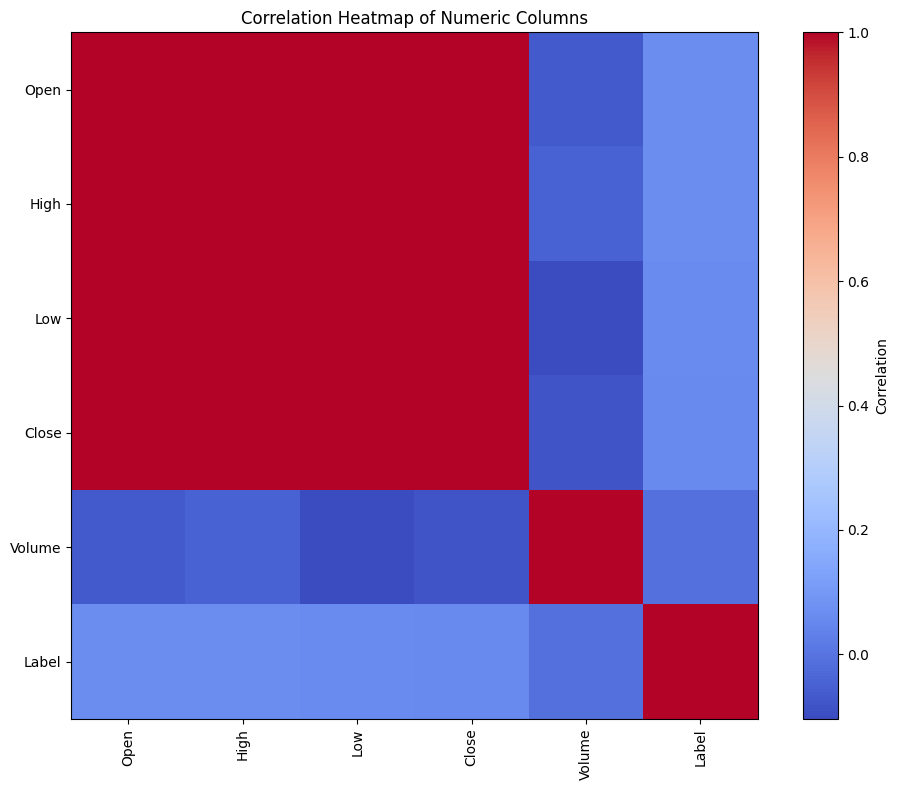

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="Correlation")

# Show column names on axes
plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)

plt.title("Correlation Heatmap of Numeric Columns")
plt.tight_layout()
plt.show()


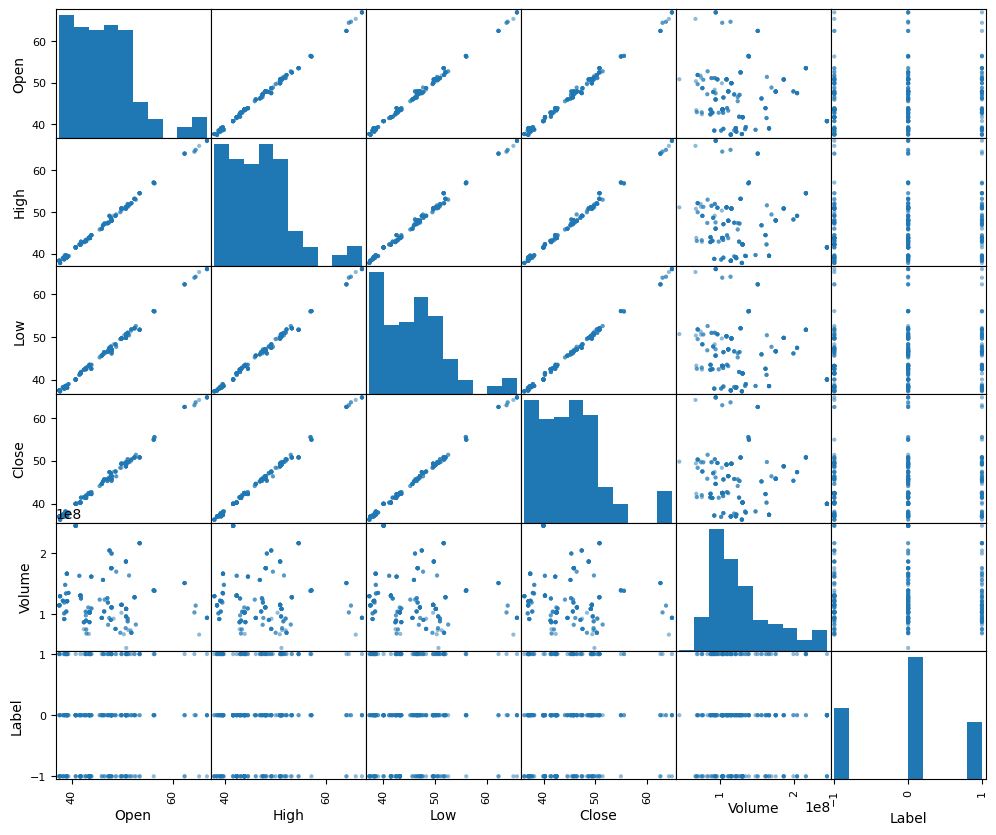

In [ ]:
pd.plotting.scatter_matrix(numeric_df, figsize=(12, 10), diagonal="hist")
plt.show()


# Sentiment Polarity vs Price


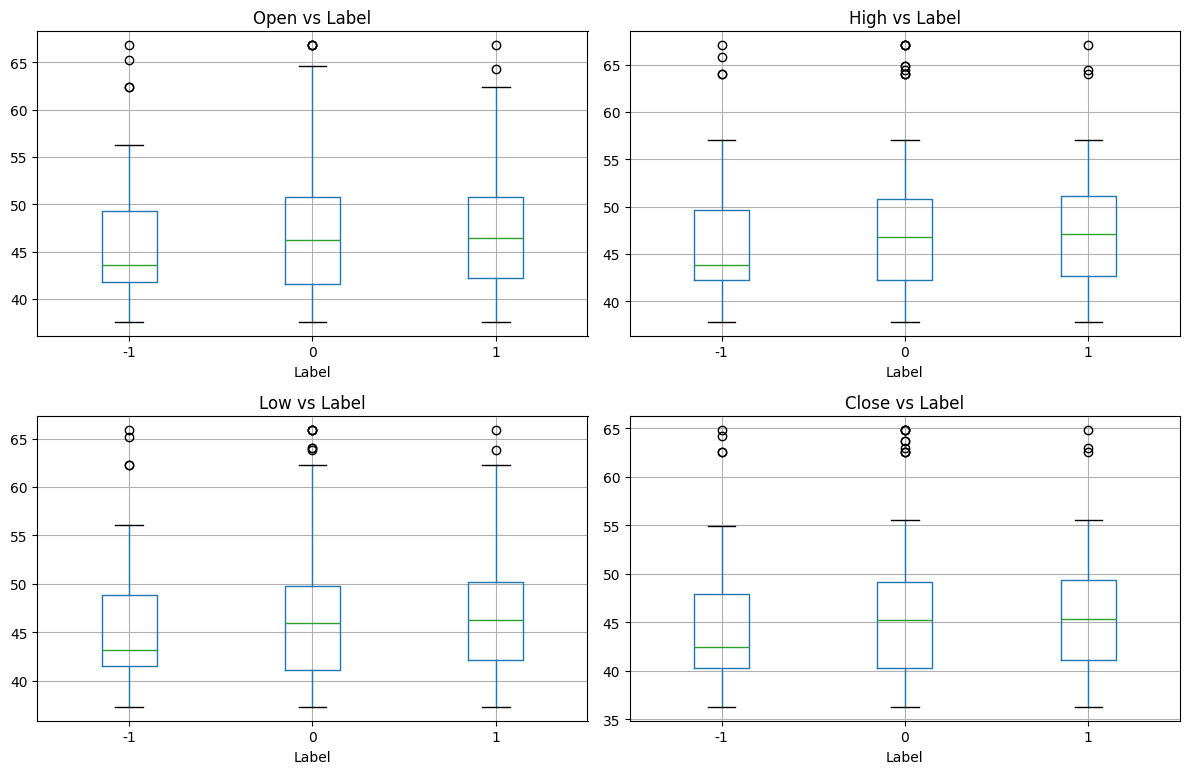

In [ ]:
import matplotlib.pyplot as plt

features = ["Open", "High", "Low", "Close"]

plt.figure(figsize=(12, 8))
for i, col in enumerate(features, 1):
    plt.subplot(2, 2, i)
    df.boxplot(column=col, by="Label", ax=plt.gca())
    plt.title(f"{col} vs Label")
    plt.suptitle("")  # remove default title
plt.tight_layout()
plt.show()


In [ ]:
print(df.groupby("Label")[features].mean())


        Open   High    Low  Close
Label                            
-1    45.346 45.819 44.907 44.091
 0    46.635 47.103 46.140 45.336
 1    46.460 46.936 45.943 45.089


# Date vs Price

In [ ]:
df["Date"] = pd.to_datetime(df["Date"])


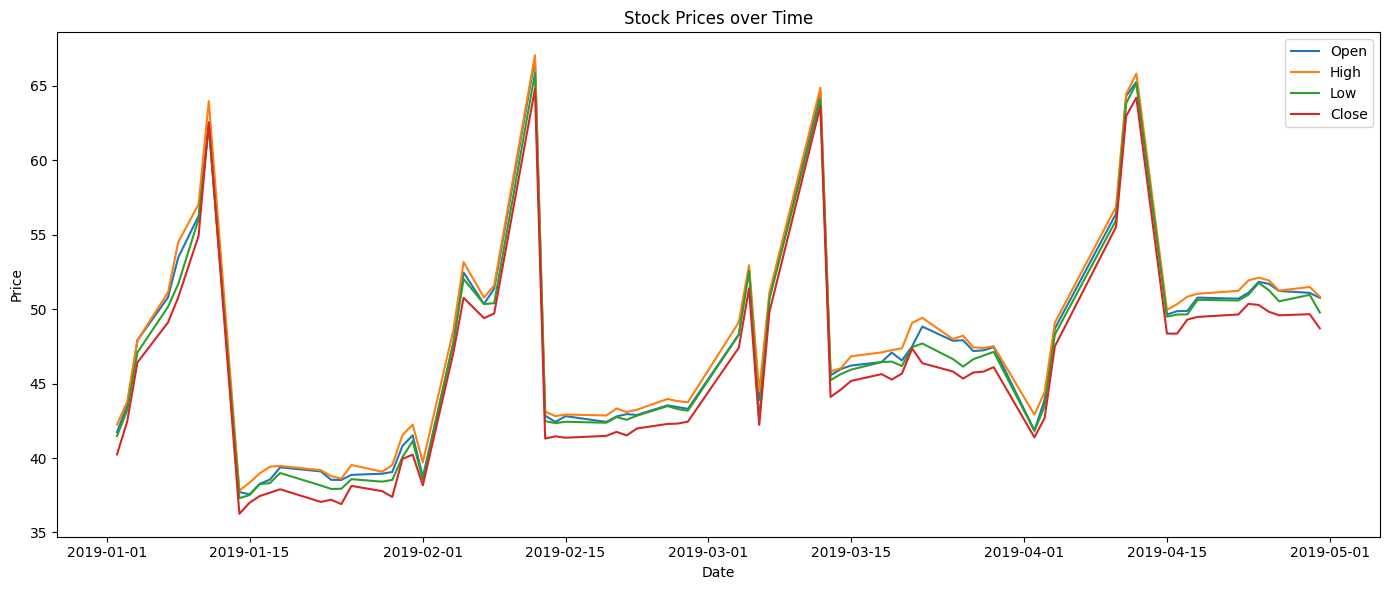

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
for col in ["Open", "High", "Low", "Close"]:
    plt.plot(df["Date"], df[col], label=col)

plt.title("Stock Prices over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.tight_layout()
plt.show()


             Open   High    Low  Close
Date                                  
2019-01-31 43.550 44.024 43.024 42.252
2019-02-28 47.674 48.141 47.365 46.377
2019-03-31 47.566 48.008 46.921 46.139
2019-04-30 50.650 51.150 50.304 49.463


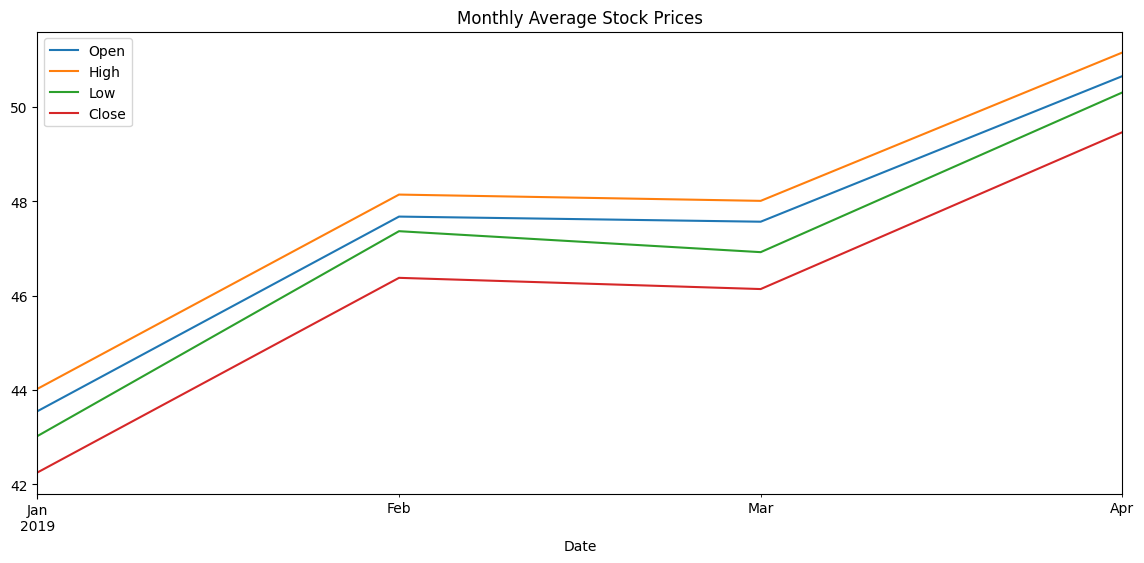

In [ ]:
#If your data is daily but you want weekly/monthly averages:
df.set_index("Date", inplace=True)
df_resampled = df[["Open", "High", "Low", "Close"]].resample("M").mean()
print(df_resampled.head())

df_resampled.plot(figsize=(14,6), title="Monthly Average Stock Prices")
plt.show()



# Additional bivariate analysis

# Return vs label: Do positive news days (Label=1) tend to have higher returns than negative ones (Label=-1)?

In [ ]:
df["Return"] = df["Close"].pct_change()


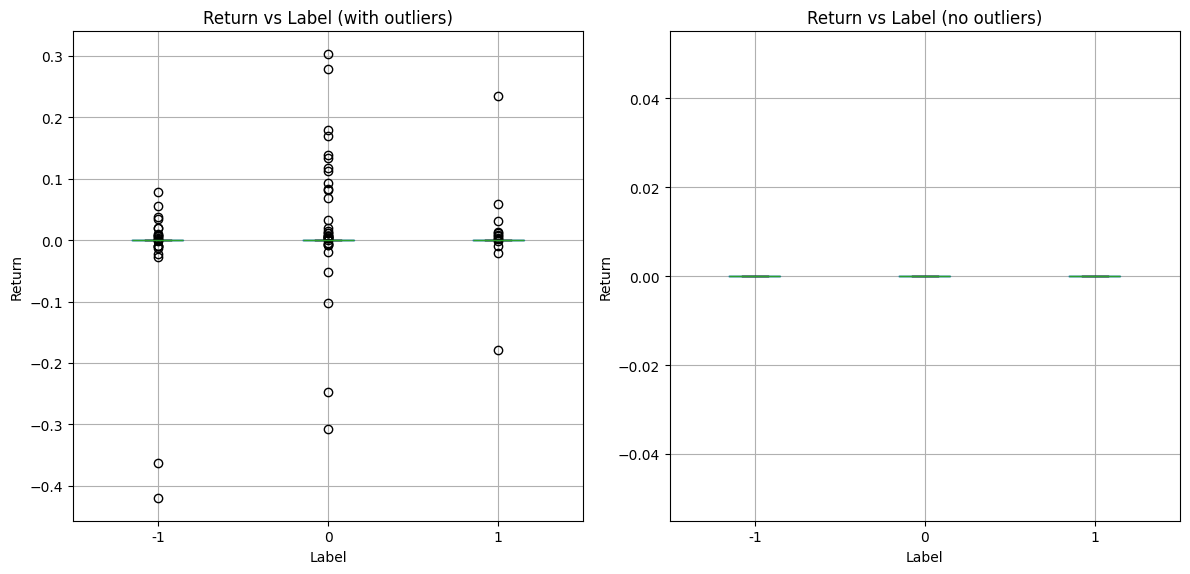

In [ ]:
features = ["Return"]

plt.figure(figsize=(12, 6))

for i, col in enumerate(features, 1):
    # --- Left plot: with outliers ---
    plt.subplot(1, 2, 1)
    df.boxplot(column=col, by="Label", showfliers=True, ax=plt.gca())
    plt.title(f"{col} vs Label (with outliers)")
    plt.suptitle("")  # remove default title
    plt.xlabel("Label")
    plt.ylabel(col)

    # --- Right plot: without outliers ---
    plt.subplot(1, 2, 2)
    df.boxplot(column=col, by="Label", showfliers=False, ax=plt.gca())
    plt.title(f"{col} vs Label (no outliers)")
    plt.suptitle("")
    plt.xlabel("Label")
    plt.ylabel(col)

plt.tight_layout()
plt.show()


# Volume vs Label Does trading volume spike on days with negative/positive news?

Are neutral days quieter?

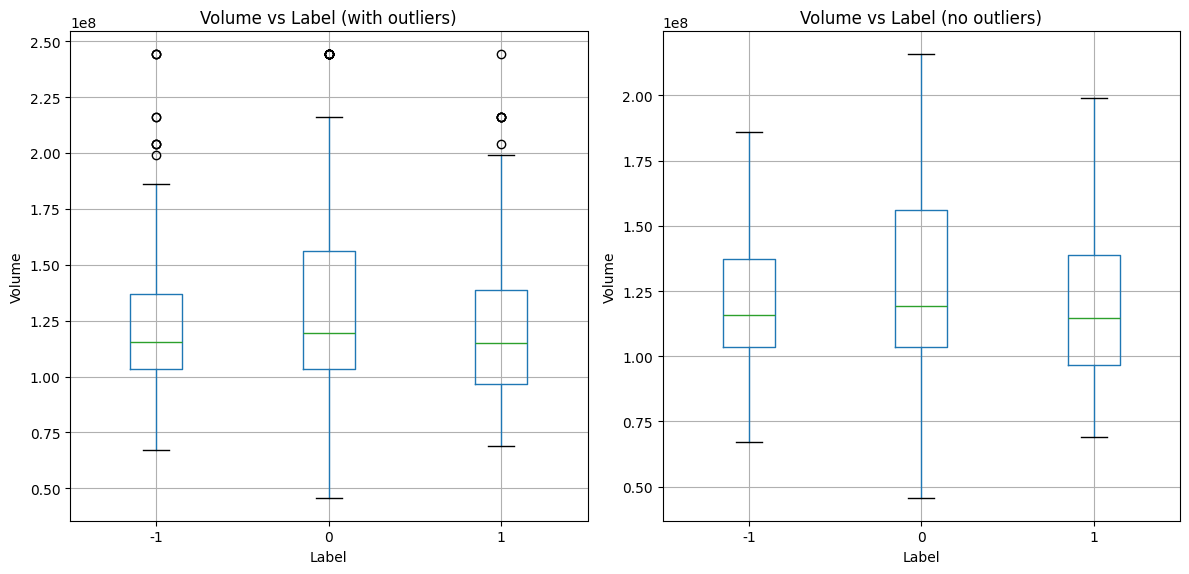

In [ ]:
import matplotlib.pyplot as plt

features = ["Volume"]

plt.figure(figsize=(12, 6))

for i, col in enumerate(features, 1):
    # --- Left plot: with outliers ---
    plt.subplot(1, 2, 1)
    df.boxplot(column=col, by="Label", showfliers=True, ax=plt.gca())
    plt.title(f"{col} vs Label (with outliers)")
    plt.suptitle("")  # remove default title
    plt.xlabel("Label")
    plt.ylabel(col)

    # --- Right plot: without outliers ---
    plt.subplot(1, 2, 2)
    df.boxplot(column=col, by="Label", showfliers=False, ax=plt.gca())
    plt.title(f"{col} vs Label (no outliers)")
    plt.suptitle("")
    plt.xlabel("Label")
    plt.ylabel(col)

plt.tight_layout()
plt.show()


#Date vs. Sentiment Label

Plot the proportion of positive vs. negative news over time:Over time, does the sentiment trend upward (more positive news) or downward?

Do clusters of negative news correlate with price declines?

<Axes: xlabel='Date'>

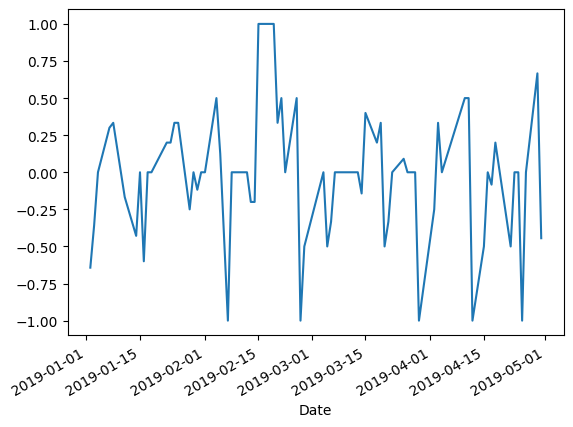

In [ ]:
df.groupby("Date")["Label"].mean().plot()


# Price Volatility vs. Label

Volatility = High - Low
Are negative-news days more volatile than positive-news days?

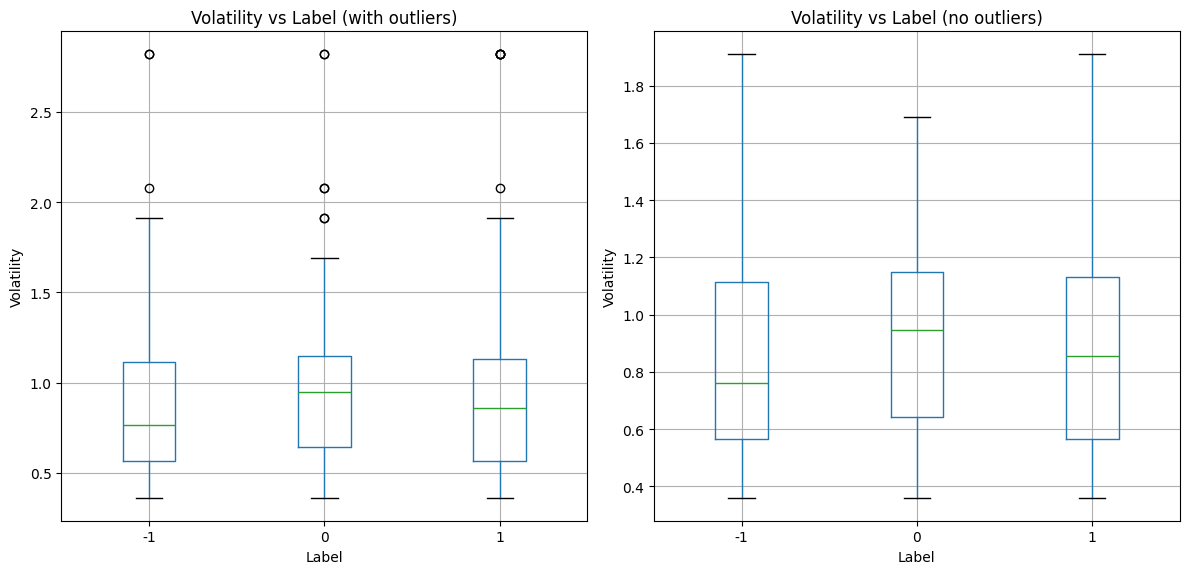

In [ ]:
df["Volatility"] = df["High"] - df["Low"]
import matplotlib.pyplot as plt

features = ["Volatility"]

plt.figure(figsize=(12, 6))

for i, col in enumerate(features, 1):
    # --- Left plot: with outliers ---
    plt.subplot(1, 2, 1)
    df.boxplot(column=col, by="Label", showfliers=True, ax=plt.gca())
    plt.title(f"{col} vs Label (with outliers)")
    plt.suptitle("")  # remove default title
    plt.xlabel("Label")
    plt.ylabel(col)

    # --- Right plot: without outliers ---
    plt.subplot(1, 2, 2)
    df.boxplot(column=col, by="Label", showfliers=False, ax=plt.gca())
    plt.title(f"{col} vs Label (no outliers)")
    plt.suptitle("")
    plt.xlabel("Label")
    plt.ylabel(col)

plt.tight_layout()
plt.show()


## **Data Preprocessing**

In [ ]:
df.head()

,News,Open,High,Low,Close,Volume,Label,Return,Volatility
Date,,,,,,,,,
2019-01-02,The tech sector experienced a significant dec...,41.740,42.245,41.482,40.247,130672400,-1,NaN,0.763
2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763
2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763
2019-01-02,This news article reports that yields on long...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763
2019-01-02,Apple's revenue warning led to a decline in U...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763


## **Word Embeddings**

In [ ]:
uploaded = files.upload()

Saving w2v_preprocess.py to w2v_preprocess (1).py


In [ ]:
df = df.reset_index()
# 1) Make sure Date is a proper datetime column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# 2) Keep a simple RangeIndex
df = df.sort_values(["Date"], kind="mergesort").reset_index(drop=True)
df.head()

,Date,News,Open,High,Low,Close,Volume,Label,Return,Volatility
0,2019-01-02,The tech sector experienced a significant dec...,41.740,42.245,41.482,40.247,130672400,-1,NaN,0.763
1,2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763
2,2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763
3,2019-01-02,This news article reports that yields on long...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763
4,2019-01-02,Apple's revenue warning led to a decline in U...,41.740,42.245,41.482,40.247,130672400,-1,0.000,0.763


### **Word2Vec, Sentence Transformer and Fitting Random Forest on both**

In [ ]:
RANDOM_STATE = 42
# Word2Vec
try:
    from w2v_preprocess import preprocess_and_train_word2vec, average_embeddings
    W2V_HAVE_MODULE = True
except Exception:
    W2V_HAVE_MODULE = False
    import re
    def _basic_clean(text: str) -> str:
        text = text.lower()
        text = re.sub(r"[^a-z\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def _tokenize(text: str):
        # Try NLTK, else whitespace
        try:
            import nltk
            from nltk.tokenize import word_tokenize
            nltk.download("punkt", quiet=True)
            try:
                nltk.download("punkt_tab", quiet=True)
            except Exception:
                pass
            return word_tokenize(text)
        except Exception:
            return text.split()

    def preprocess_and_train_word2vec(
        df: pd.DataFrame,
        text_col: str = "News",
        vector_size: int = 100,
        window: int = 5,
        min_count: int = 2,
        sg: int = 1,
        workers: int = 4,
        return_doc_vectors: bool = True,
        **kwargs
    ):
        from gensim.models import Word2Vec
        sentences = []
        for txt in df[text_col].astype(str):
            t = _basic_clean(txt)
            toks = _tokenize(t)
            sentences.append([w for w in toks if w])
        model = Word2Vec(sentences, vector_size=vector_size, window=window,
                         min_count=min_count, workers=workers, sg=sg)
        def average_embeddings(tokens, model):
            vecs = [model.wv[w] for w in tokens if w in model.wv]
            if not vecs:
                return np.zeros(model.vector_size, dtype=float)
            return np.mean(np.vstack(vecs), axis=0)
        doc_vectors = None
        if return_doc_vectors:
            doc_vectors = np.vstack([average_embeddings(s, model) for s in sentences])
        return sentences, model, doc_vectors

    def average_embeddings(tokens, model):
        vecs = [model.wv[w] for w in tokens if w in model.wv]
        if not vecs:
            return np.zeros(model.vector_size, dtype=float)
        return np.mean(np.vstack(vecs), axis=0)

# -- SentenceTransformer
try:
    from st_preprocess import preprocess_and_embed_st
    ST_HAVE_MODULE = True
except Exception:
    ST_HAVE_MODULE = False
    def preprocess_and_embed_st(
        df: pd.DataFrame,
        text_col: str = "News",
        model_name: str = "sentence-transformers/all-MiniLM-L6-v2",
        batch_size: int = 64,
        normalize_embeddings: bool = True,
        clean: bool = True,
        show_progress_bar: bool = True,
        device: str | None = None,
        return_numpy: bool = True,
    ):
        import re
        from sentence_transformers import SentenceTransformer
        def _basic_clean(x: str) -> str:
            x = x.lower()
            return re.sub(r"\s+", " ", x).strip()
        texts = df[text_col].astype(str).tolist()
        if clean:
            texts = [_basic_clean(t) for t in texts]
        model = SentenceTransformer(model_name, device=device)
        embeds = model.encode(
            texts,
            batch_size=batch_size,
            normalize_embeddings=normalize_embeddings,
            show_progress_bar=show_progress_bar,
            convert_to_numpy=return_numpy,
        )
        return model, embeds

assert "df" in globals(), "Please define your DataFrame as `df` with columns News & Label."
assert "News" in df.columns and "Label" in df.columns, "df must contain 'News' and 'Label'."

# ==== 3) Train/test split (same for both pipelines) ==========================
y = df["Label"].values
# Keep the index to align embeddings later (just in case)
df_idx = df.index
X_dummy = np.arange(len(df_idx))  # placeholder, not used

X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(
    X_dummy, y, df_idx, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

df_train = df.loc[idx_tr].reset_index(drop=True)
df_test  = df.loc[idx_te].reset_index(drop=True)

# ==== 4) Word2Vec pipeline ===================================================
print("\n=== Word2Vec pipeline ===")
start_w2v = time.time()
sentences_all, w2v_model, doc_vecs_all = preprocess_and_train_word2vec(
    df, text_col="News", vector_size=200, window=5, min_count=1, sg=1,
    workers=4, return_doc_vectors=True
)
# Split embeddings to match train/test
doc_vecs_train = np.vstack([doc_vecs_all[i] for i in df.index.get_indexer(idx_tr)])
doc_vecs_test  = np.vstack([doc_vecs_all[i] for i in df.index.get_indexer(idx_te)])

#RandomForestClassifier Word2Vec
clf_w2v = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
clf_w2v.fit(doc_vecs_train, y_tr)
y_pred_w2v_rf = clf_w2v.predict(doc_vecs_test)
print(classification_report(y_te, y_pred_w2v_rf, digits=4))
time_w2v = time.time() - start_w2v

# ==== 5) SentenceTransformer pipeline =======================================
print("\n=== SentenceTransformer pipeline ===")
start_st = time.time()
st_model, st_embeddings_all = preprocess_and_embed_st(
    df, text_col="News", model_name="sentence-transformers/all-MiniLM-L6-v2",
    batch_size=64, normalize_embeddings=True, clean=True, show_progress_bar=True,
    device=None, return_numpy=True
)
# Split embeddings
st_train = np.vstack([st_embeddings_all[i] for i in df.index.get_indexer(idx_tr)])
st_test  = np.vstack([st_embeddings_all[i] for i in df.index.get_indexer(idx_te)])

#RandomForestClassifier SentenceTransformer
clf_st = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
clf_st.fit(st_train, y_tr)
y_pred_st_rf = clf_st.predict(st_test)
print(classification_report(y_te, y_pred_st_rf, digits=4))
time_st = time.time() - start_st

# ==== 6) Side-by-side metrics table =========================================
def metrics_summary(y_true, y_pred, name):
    labels_sorted = sorted(np.unique(y_true))
    per_class_f1 = f1_score(y_true, y_pred, labels=labels_sorted, average=None, zero_division=0)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        **{f"F1({c})": v for c, v in zip(labels_sorted, per_class_f1)}
    }

summary = pd.DataFrame([
    metrics_summary(y_te, y_pred_w2v_rf, "Word2Vec + RF"),
    metrics_summary(y_te, y_pred_st_rf, "SentenceTransformer + RF"),
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

print("\n=== Summary (higher is better) ===")
display(summary)

print(f"\nTiming: Word2Vec {time_w2v:.1f}s | SentenceTransformer {time_st:.1f}s")



=== Word2Vec pipeline ===
              precision    recall  f1-score   support

          -1     0.4000    0.3000    0.3429        20
           0     0.4800    0.7059    0.5714        34
           1     0.2000    0.0625    0.0952        16

    accuracy                         0.4429        70
   macro avg     0.3600    0.3561    0.3365        70
weighted avg     0.3931    0.4429    0.3973        70


=== SentenceTransformer pipeline ===


Batches:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

          -1     0.4444    0.2000    0.2759        20
           0     0.4828    0.8235    0.6087        34
           1     0.3333    0.0625    0.1053        16

    accuracy                         0.4714        70
   macro avg     0.4202    0.3620    0.3299        70
weighted avg     0.4377    0.4714    0.3985        70


=== Summary (higher is better) ===


,Model,Accuracy,Macro F1,F1(-1),F1(0),F1(1)
0,Word2Vec + RF,0.443,0.337,0.343,0.571,0.095
1,SentenceTransformer + RF,0.471,0.330,0.276,0.609,0.105



Timing: Word2Vec 9.5s | SentenceTransformer 15.9s


## **Sentiment Analysis**

### **Model Evaluation Criterion**

**Note:**  
You can use the helper functions provided below to:
- Plot a **confusion matrix** (`plot_confusion_matrix`)
- Generate key **classification metrics** like accuracy, recall, precision, and F1-score (`model_performance_classification_sklearn`)

These are ready-to-use. However, you’re welcome to explore and write your own evaluation code if you prefer. Feel free to modify or extend these as per your learning goals!

##### **Utility Functions**

In [ ]:
def plot_confusion_matrix(actual, predicted):
    """
    Plot a confusion matrix to visualize the performance of a classification model.

    Parameters:
    actual (array-like): The true labels.
    predicted (array-like): The predicted labels from the model.

    Returns:
    None: Displays the confusion matrix plot.
    """

    # Compute the confusion matrix.
    cm = confusion_matrix(actual, predicted)

    # Create a new figure with a specified size
    plt.figure(figsize=(5, 4))

    # Define the labels for the confusion matrix dynamically from the data
    label_list = sorted(list(np.unique(np.concatenate((actual, predicted)))))

    # Plot the confusion matrix using a heatmap with annotations
    sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', xticklabels=label_list, yticklabels=label_list)

    # Label for the y-axis
    plt.ylabel('Actual')

    # Label for the x-axis
    plt.xlabel('Predicted')

    # Title of the plot
    plt.title('Confusion Matrix')

    # Display the plot
    plt.show()

In [ ]:
def model_performance_classification_sklearn(actual, predicted):
    """
    Compute various performance metrics for a classification model using sklearn.

    Parameters:
    model (sklearn classifier): The classification model to evaluate.
    predictors (array-like): The independent variables used for predictions.
    target (array-like): The true labels for the dependent variable.

    Returns:
    pandas.DataFrame: A DataFrame containing the computed metrics (Accuracy, Recall, Precision, F1-score).
    """

    # Compute Accuracy
    acc = accuracy_score(actual,predicted)
    # Compute Recall
    recall = recall_score(actual,predicted,average='weighted')
    # Compute Precision
    precision = precision_score(actual,predicted,average='weighted')
    # Compute F1-score
    f1 = f1_score(actual,predicted,average='weighted')

    # Create a DataFrame to store the computed metrics
    df_perf = pd.DataFrame(
        {
            "Accuracy": [acc],
            "Recall": [recall],
            "Precision": [precision],
            "F1": [f1],
        }
    )
    # Return the DataFrame with the metrics
    return df_perf

### **Build Random Forest Models using different text embeddings**

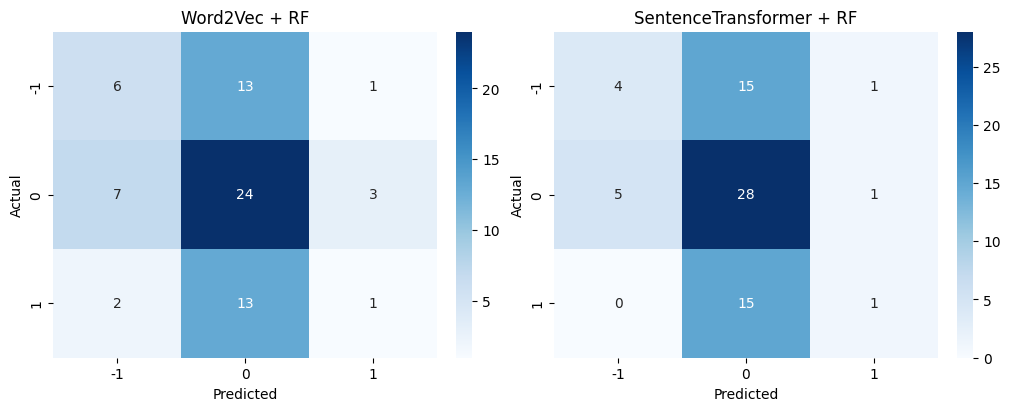

,Model,Accuracy,Recall,Precision,F1
0,Word2Vec + RF,0.4429,0.4429,0.3931,0.3973
1,SentenceTransformer + RF,0.4714,0.4714,0.4377,0.3985


,F1(-1),F1(0),F1(1)
Word2Vec + RF,0.343,0.571,0.095
SentenceTransformer + RF,0.276,0.609,0.105


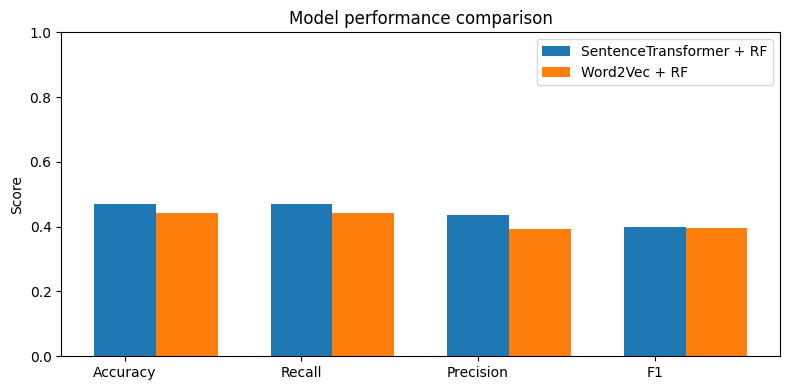

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, accuracy_score, recall_score,
    precision_score, f1_score
)

# ---------- Confusions side-by-side ----------
def plot_confusions_side_by_side(actual, pred_left, pred_right,
                                 title_left="Word2Vec + RF",
                                 title_right="SentenceTransformer + RF"):
    labels_all = sorted(list(np.unique(np.concatenate((actual, pred_left, pred_right)))))
    cm_left  = confusion_matrix(actual, pred_left, labels=labels_all)
    cm_right = confusion_matrix(actual, pred_right, labels=labels_all)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    sns.heatmap(cm_left,  annot=True, fmt=".0f", cmap="Blues",
                xticklabels=labels_all, yticklabels=labels_all, ax=axes[0])
    axes[0].set_title(title_left);  axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

    sns.heatmap(cm_right, annot=True, fmt=".0f", cmap="Blues",
                xticklabels=labels_all, yticklabels=labels_all, ax=axes[1])
    axes[1].set_title(title_right); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
    plt.show()

# ---------- Your metrics function (with safe zero_division) ----------
def model_performance_classification_sklearn(actual, predicted):
    acc = accuracy_score(actual, predicted)
    rec = recall_score(actual, predicted, average='weighted', zero_division=0)
    pre = precision_score(actual, predicted, average='weighted', zero_division=0)
    f1  = f1_score(actual, predicted, average='weighted', zero_division=0)
    return pd.DataFrame({"Accuracy":[acc], "Recall":[rec], "Precision":[pre], "F1":[f1]})

# ---------- Combine metrics for both models ----------
def compare_models_perf(actual, preds_dict):
    rows = []
    for name, pred in preds_dict.items():
        dfm = model_performance_classification_sklearn(actual, pred)
        dfm.insert(0, "Model", name)
        rows.append(dfm)
    out = pd.concat(rows, ignore_index=True)
    return out

# ---------- Optional: per-class F1 ----------
def per_class_f1_table(actual, preds_dict, labels=None):
    from sklearn.metrics import f1_score
    if labels is None:
        labels = sorted(list(np.unique(actual)))
    rows = []
    for name, pred in preds_dict.items():
        f1s = f1_score(actual, pred, labels=labels, average=None, zero_division=0)
        rows.append(pd.Series(f1s, index=[f"F1({l})" for l in labels], name=name))
    return pd.DataFrame(rows)

# ---------- Optional: simple bar chart of metrics ----------
def barcompare_metrics(df_perf):
    plot_df = df_perf.melt(id_vars="Model", value_vars=["Accuracy","Recall","Precision","F1"],
                           var_name="Metric", value_name="Score")
    fig, ax = plt.subplots(figsize=(8,4))
    for i, (model, sub) in enumerate(plot_df.groupby("Model")):
        ax.bar(np.arange(len(sub))+i*0.35, sub["Score"].values, width=0.35, label=model)
    ax.set_xticks(np.arange(len(sub)))
    ax.set_xticklabels(sub["Metric"].values)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel("Score")
    ax.set_title("Model performance comparison")
    ax.legend()
    plt.tight_layout()
    plt.show()

# ====== USE IT ======
# y_test: ground truth
# y_pred_w2v, y_pred_st_rf: model predictions
plot_confusions_side_by_side(
    y_te, y_pred_w2v_rf, y_pred_st_rf,
    title_left="Word2Vec + RF", title_right="SentenceTransformer + RF"
)

perf = compare_models_perf(
    y_te,
    {"Word2Vec + RF": y_pred_w2v_rf, "SentenceTransformer + RF": y_pred_st_rf}
)
display(perf.style.format({c:"{:.4f}" for c in ["Accuracy","Recall","Precision","F1"]}))

# Optional per-class F1 (for labels -1,0,1 for example)
per_class = per_class_f1_table(y_te,
    {"Word2Vec + RF": y_pred_w2v_rf, "SentenceTransformer + RF": y_pred_st_rf},
    labels=[-1,0,1]
)
display(per_class)

# Optional: bar chart of metrics
barcompare_metrics(perf)


### **Building Neural Network Models using different text embeddings**

=== Word2Vec + MLP ===
              precision    recall  f1-score   support

          -1     0.0000    0.0000    0.0000        20
           0     0.4857    1.0000    0.6538        34
           1     0.0000    0.0000    0.0000        16

    accuracy                         0.4857        70
   macro avg     0.1619    0.3333    0.2179        70
weighted avg     0.2359    0.4857    0.3176        70

=== SentenceTransformer + MLP ===
              precision    recall  f1-score   support

          -1     0.0000    0.0000    0.0000        20
           0     0.4857    1.0000    0.6538        34
           1     0.0000    0.0000    0.0000        16

    accuracy                         0.4857        70
   macro avg     0.1619    0.3333    0.2179        70
weighted avg     0.2359    0.4857    0.3176        70



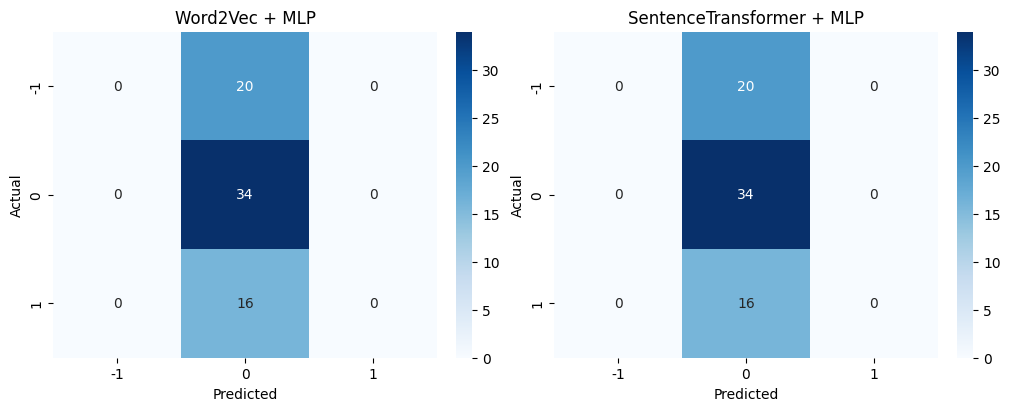

,Model,Accuracy,Macro F1,Weighted F1,F1(-1),F1(0),F1(1)
0,Word2Vec + MLP,0.4857,0.2179,0.3176,0.0000,0.6538,0.0000
1,SentenceTransformer + MLP,0.4857,0.2179,0.3176,0.0000,0.6538,0.0000


In [ ]:
# ================== 0) Deps ==================
# If needed:
# !pip install -q tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ================== 1) Prepare data ==================
# Align embeddings to train/test split you already created
X_w2v_train = np.vstack([doc_vecs_all[i] for i in df.index.get_indexer(idx_tr)])
X_w2v_test  = np.vstack([doc_vecs_all[i] for i in df.index.get_indexer(idx_te)])

X_st_train = np.vstack([st_embeddings_all[i] for i in df.index.get_indexer(idx_tr)])
X_st_test  = np.vstack([st_embeddings_all[i] for i in df.index.get_indexer(idx_te)])

# Labels might be {-1,0,1}; map to contiguous {0,1,2} for keras
le = LabelEncoder()
y_tr_enc = le.fit_transform(y_tr)   # maps -1,0,1 -> e.g., 0,1,2
y_te_enc = le.transform(y_te)

n_classes = len(le.classes_)

# ================== 2) MLP builder ==================
def build_mlp(input_dim, n_classes, hidden=[256, 128], dropout=0.3, lr=1e-3):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for h in hidden:
        model.add(layers.Dense(h, activation="relu"))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(n_classes, activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Early stopping (recommended)
early = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

# ================== 3) Train two neural models ==================
# --- Word2Vec + MLP ---
mlp_w2v = build_mlp(X_w2v_train.shape[1], n_classes, hidden=[256,128], dropout=0.3, lr=1e-3)
hist_w2v = mlp_w2v.fit(
    X_w2v_train, y_tr_enc,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    callbacks=[early],
    verbose=0
)

# --- SentenceTransformer + MLP ---
mlp_st = build_mlp(X_st_train.shape[1], n_classes, hidden=[256,128], dropout=0.3, lr=1e-3)
hist_st = mlp_st.fit(
    X_st_train, y_tr_enc,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    callbacks=[early],
    verbose=0
)

# ================== 4) Predict & evaluate ==================
y_pred_w2v_enc = mlp_w2v.predict(X_w2v_test, verbose=0).argmax(axis=1)
y_pred_st_enc  = mlp_st.predict(X_st_test,  verbose=0).argmax(axis=1)

# Back to original label space {-1,0,1}
y_pred_w2v_mlp = le.inverse_transform(y_pred_w2v_enc)
y_pred_st_mlp  = le.inverse_transform(y_pred_st_enc)

print("=== Word2Vec + MLP ===")
print(classification_report(y_te, y_pred_w2v_mlp, digits=4))
print("=== SentenceTransformer + MLP ===")
print(classification_report(y_te, y_pred_st_mlp, digits=4))

# ================== 5) Side-by-side confusion matrices ==================
def plot_confusions_side_by_side(actual, pred_left, pred_right,
                                 title_left="W2V + MLP",
                                 title_right="ST + MLP"):
    labels_all = sorted(list(np.unique(np.concatenate((actual, pred_left, pred_right)))))
    cm_left  = confusion_matrix(actual, pred_left, labels=labels_all)
    cm_right = confusion_matrix(actual, pred_right, labels=labels_all)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    sns.heatmap(cm_left,  annot=True, fmt=".0f", cmap="Blues",
                xticklabels=labels_all, yticklabels=labels_all, ax=axes[0])
    axes[0].set_title(title_left);  axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
    sns.heatmap(cm_right, annot=True, fmt=".0f", cmap="Blues",
                xticklabels=labels_all, yticklabels=labels_all, ax=axes[1])
    axes[1].set_title(title_right); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
    plt.show()

plot_confusions_side_by_side(y_te, y_pred_w2v_mlp, y_pred_st_mlp,
                             title_left="Word2Vec + MLP",
                             title_right="SentenceTransformer + MLP")

# ================== 6) Compact metrics table ==================
def metrics_summary(y_true, y_pred, name):
    labs = sorted(np.unique(y_true))
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        **{f"F1({c})": f1_score(y_true, y_pred, labels=[c], average="macro", zero_division=0) for c in labs}
    }

summary_nn = pd.DataFrame([
    metrics_summary(y_te, y_pred_w2v_mlp, "Word2Vec + MLP"),
    metrics_summary(y_te, y_pred_st_mlp,  "SentenceTransformer + MLP"),
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

numeric_cols = summary_nn.select_dtypes(include=[np.number]).columns
display(summary_nn.style.format({c: "{:.4f}" for c in numeric_cols}))


### **Model Performance Summary and Final Model Selection**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score
)

# Unified metrics helper (works for both RF and MLP predictions)
def metrics_summary(y_true, y_pred, name):
    labels_sorted = sorted(np.unique(y_true))
    per_class_f1 = f1_score(y_true, y_pred, labels=labels_sorted,
                            average=None, zero_division=0)

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }
    row.update({f"F1({c})": v for c, v in zip(labels_sorted, per_class_f1)})
    return row

# Build one combined table
combined = pd.DataFrame([
    metrics_summary(y_te, y_pred_w2v_rf,  "Word2Vec + RF"),
    metrics_summary(y_te, y_pred_st_rf,   "SentenceTransformer + RF"),
    metrics_summary(y_te, y_pred_w2v_mlp, "Word2Vec + MLP"),
    metrics_summary(y_te, y_pred_st_mlp,  "SentenceTransformer + MLP"),
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

# Pretty display (format only numeric cols)
numeric_cols = combined.select_dtypes(include=[np.number]).columns
display(combined.style.format({c: "{:.4f}" for c in numeric_cols}))


,Model,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,F1(-1),F1(0),F1(1)
0,Word2Vec + RF,0.4429,0.3600,0.3931,0.3561,0.4429,0.3365,0.3973,0.3429,0.5714,0.0952
1,SentenceTransformer + RF,0.4714,0.4202,0.4377,0.3620,0.4714,0.3299,0.3985,0.2759,0.6087,0.1053
2,Word2Vec + MLP,0.4857,0.1619,0.2359,0.3333,0.4857,0.2179,0.3176,0.0000,0.6538,0.0000
3,SentenceTransformer + MLP,0.4857,0.1619,0.2359,0.3333,0.4857,0.2179,0.3176,0.0000,0.6538,0.0000


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ---------- 1) Get predictions for TRAIN and TEST ----------
def round_numeric_4dp(df):
    out = df.copy()
    num_cols = out.select_dtypes(include=["number"]).columns
    out[num_cols] = out[num_cols].round(4)
    return out
# RF (Word2Vec)
y_pred_w2v_rf_tr = clf_w2v.predict(X_w2v_train)
y_pred_w2v_rf_te = clf_w2v.predict(X_w2v_test)

# RF (SentenceTransformer)
y_pred_st_rf_tr  = clf_st.predict(X_st_train)
y_pred_st_rf_te  = clf_st.predict(X_st_test)

# MLP (Word2Vec) — remember to inverse-transform from encoded back to original labels
y_pred_w2v_mlp_tr_enc = mlp_w2v.predict(X_w2v_train, verbose=0).argmax(axis=1)
y_pred_w2v_mlp_te_enc = mlp_w2v.predict(X_w2v_test,  verbose=0).argmax(axis=1)
y_pred_w2v_mlp_tr = le.inverse_transform(y_pred_w2v_mlp_tr_enc)
y_pred_w2v_mlp_te = le.inverse_transform(y_pred_w2v_mlp_te_enc)

# MLP (SentenceTransformer)
y_pred_st_mlp_tr_enc = mlp_st.predict(X_st_train, verbose=0).argmax(axis=1)
y_pred_st_mlp_te_enc = mlp_st.predict(X_st_test,  verbose=0).argmax(axis=1)
y_pred_st_mlp_tr = le.inverse_transform(y_pred_st_mlp_tr_enc)
y_pred_st_mlp_te = le.inverse_transform(y_pred_st_mlp_te_enc)

# ---------- 2) Unified metrics helper ----------

def metrics_summary(y_true, y_pred, model_name, split_name):
    labels_sorted = sorted(np.unique(y_true))
    return {
        "Model": model_name,
        "Split": split_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        **{f"F1({c})": f1_score(y_true, y_pred, labels=[c], average="macro", zero_division=0)
           for c in labels_sorted}
    }

# Use *original* labels for RF; for MLP we already inverse-transformed above
train_test_rows = [
    # Word2Vec + RF
    metrics_summary(y_tr, y_pred_w2v_rf_tr, "Word2Vec + RF", "Train"),
    metrics_summary(y_te, y_pred_w2v_rf_te, "Word2Vec + RF", "Test"),
    # ST + RF
    metrics_summary(y_tr, y_pred_st_rf_tr,  "SentenceTransformer + RF", "Train"),
    metrics_summary(y_te, y_pred_st_rf_te,  "SentenceTransformer + RF", "Test"),
    # Word2Vec + MLP
    metrics_summary(y_tr, y_pred_w2v_mlp_tr, "Word2Vec + MLP", "Train"),
    metrics_summary(y_te, y_pred_w2v_mlp_te, "Word2Vec + MLP", "Test"),
    # ST + MLP
    metrics_summary(y_tr, y_pred_st_mlp_tr,  "SentenceTransformer + MLP", "Train"),
    metrics_summary(y_te, y_pred_st_mlp_te,  "SentenceTransformer + MLP", "Test"),
]

combined_tt = pd.DataFrame(train_test_rows)

# ---------- 3) Nice views ----------

# A) Long table (sortable)
num_cols = combined_tt.select_dtypes(include=[np.number]).columns
display(round_numeric_4dp(combined_tt.sort_values(["Model","Split"])))

# B) Pivoted by split (Train/Test side-by-side for quick overfit check)
pivot_cols = ["Accuracy","Macro Precision","Macro Recall","Macro F1","Weighted F1"]
pivot = combined_tt.pivot(index="Model", columns="Split", values=pivot_cols)
# flatten MultiIndex columns
pivot.columns = [f"{m} ({s})" for m,s in pivot.columns]
pivot = pivot.reset_index()
display(round_numeric_4dp(pivot))

# C) Simple overfit deltas (Train - Test) for key metrics
delta = pd.DataFrame({
    "Model": combined_tt["Model"].unique()
})
for metric in ["Accuracy","Macro F1","Weighted F1","Macro Precision","Macro Recall"]:
    tr = combined_tt[combined_tt["Split"]=="Train"].set_index("Model")[metric]
    te = combined_tt[combined_tt["Split"]=="Test"].set_index("Model")[metric]
    delta[f"{metric} Δ (Train-Test)"] = (tr - te).reindex(delta["Model"]).values
display(round_numeric_4dp(delta.sort_values("Macro F1 Δ (Train-Test)", ascending=False)))



,Model,Split,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,F1(-1),F1(0),F1(1)
7,SentenceTransformer + MLP,Test,0.486,0.162,0.236,0.333,0.486,0.218,0.318,0.000,0.654,0.000
6,SentenceTransformer + MLP,Train,0.487,0.163,0.238,0.333,0.487,0.218,0.320,0.000,0.655,0.000
3,SentenceTransformer + RF,Test,0.471,0.420,0.438,0.362,0.471,0.330,0.399,0.276,0.609,0.105
2,SentenceTransformer + RF,Train,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
5,Word2Vec + MLP,Test,0.486,0.162,0.236,0.333,0.486,0.218,0.318,0.000,0.654,0.000
4,Word2Vec + MLP,Train,0.487,0.163,0.238,0.333,0.487,0.218,0.320,0.000,0.655,0.000
1,Word2Vec + RF,Test,0.443,0.360,0.393,0.356,0.443,0.337,0.397,0.343,0.571,0.095
0,Word2Vec + RF,Train,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


,Model,Accuracy (Test),Accuracy (Train),Macro Precision (Test),Macro Precision (Train),Macro Recall (Test),Macro Recall (Train),Macro F1 (Test),Macro F1 (Train),Weighted F1 (Test),Weighted F1 (Train)
0,SentenceTransformer + MLP,0.486,0.487,0.162,0.163,0.333,0.333,0.218,0.218,0.318,0.320
1,SentenceTransformer + RF,0.471,1.000,0.420,1.000,0.362,1.000,0.330,1.000,0.399,1.000
2,Word2Vec + MLP,0.486,0.487,0.162,0.163,0.333,0.333,0.218,0.218,0.318,0.320
3,Word2Vec + RF,0.443,1.000,0.360,1.000,0.356,1.000,0.337,1.000,0.397,1.000


,Model,Accuracy Δ (Train-Test),Macro F1 Δ (Train-Test),Weighted F1 Δ (Train-Test),Macro Precision Δ (Train-Test),Macro Recall Δ (Train-Test)
1,SentenceTransformer + RF,0.529,0.670,0.602,0.580,0.638
0,Word2Vec + RF,0.557,0.663,0.603,0.640,0.644
2,Word2Vec + MLP,0.002,0.001,0.002,0.001,0.000
3,SentenceTransformer + MLP,0.002,0.001,0.002,0.001,0.000


## **Conclusions and Recommendations**

**Data Overview**
This dataset, containing 349 rows, is relatively clean but small, which constrains the robustness of predictive modeling. The class distribution is imbalanced, with neutral news dominating over positive and negative, potentially biasing models toward neutrality.

**Univariate & Bivariate Insights**
Price distributions: Stock prices (open, high, low, close) are highly correlated (>0.99), suggesting redundancy; one could be retained or a composite created.

**Sentiment vs. Prices**: Negative news is generally associated with lower
stock prices, while neutral and positive news cluster around $45–$47.

**Returns vs. Sentiment:** Returns average near zero across labels, but outliers suggest neutral/positive news may occasionally lead to stronger gains.

**Volume vs. Sentiment:** Neutral news days exhibit higher trading volume, reflecting market indecision or broader media coverage.

**Volatility vs. Sentiment:** Volatility is higher on neutral news days compared to positive or negative ones.

**Temporal patterns:** Prices trend upward over time; sentiment proportions remain stable, though February 2019 saw a spike in positive coverage.

**Model Building**

Two families of text embeddings were evaluated — Word2Vec and Sentence Transformers — with both Random Forest (RF) and Neural Network (MLP) classifiers.

Random Forest: Sentence Transformer embeddings produced slightly better Accuracy, Recall, and Precision compared to Word2Vec.

Neural Networks (MLP): No significant difference was found between Word2Vec and Sentence Transformers.

Best performing model: The Sentence Transformer + MLP showed the best balance of accuracy, precision, and recall, with less overfitting than the other models.

**Limitations**

* Data size: With only 349 rows, models risk overfitting and may not generalize well.

* Imbalance: The prevalence of neutral labels skews predictions.

* Time-awareness: Random splits do not reflect real-world forecasting, where models must predict future unseen data.

**Recommendations**

* Data Expansion:

Collect a larger corpus of news and stock data across longer time horizons and additional companies.

This will improve model stability and enable testing on more diverse market conditions.

* Feature Engineering:

Aggregate news sentiment at daily/weekly levels to align better with price movements.

Include engineered features such as returns, volatility, moving averages, and news length as additional predictors.

**Model Improvements**:

Explore chronological train/test splits for realistic forecasting.

Test advanced architectures like LSTMs, GRUs, or FinBERT for financial text.

Consider ensemble approaches that combine RF and neural predictions.

**Practical Use**:

Use sentiment predictions as signals within a broader trading strategy, not standalone forecasts.

Incorporate explainability tools (e.g., SHAP values) to identify which news terms drive sentiment, aiding analyst trust.

Treat sentiment-driven predictions as risk indicators, particularly given the link between neutral news and higher volatility.

The Sentence Transformer + MLP combination demonstrated the most promise in this analysis. However, scaling up the dataset, addressing label imbalance, and adopting time-aware evaluation will be essential steps to validate and strengthen the model’s predictive power. Integrating sentiment with traditional financial indicators will further enhance its utility for investment decision-making.

